# Comparing Optimization Algorithms for Linear Regression

This project investigates how different optimization algorithms affect
the training of a simple linear regression model.

The model will be trained using:
- Batch Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent
- Momentum
- Learning-rate decay

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(42)

# Display plots inside Jupyter Notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [54]:
# Independent variable: Study hours
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], dtype=float)

# Dependent variable: Exam scores
y = np.array([35, 42, 48, 55, 61, 68, 73, 81, 86, 92], dtype=float)

# Create a DataFrame to view the dataset
data = pd.DataFrame({
    "Study Hours": X,
    "Exam Score": y
})

data

,Study Hours,Exam Score
0,1.0,35.0
1,2.0,42.0
2,3.0,48.0
3,4.0,55.0
4,5.0,61.0
5,6.0,68.0
6,7.0,73.0
7,8.0,81.0
8,9.0,86.0
9,10.0,92.0


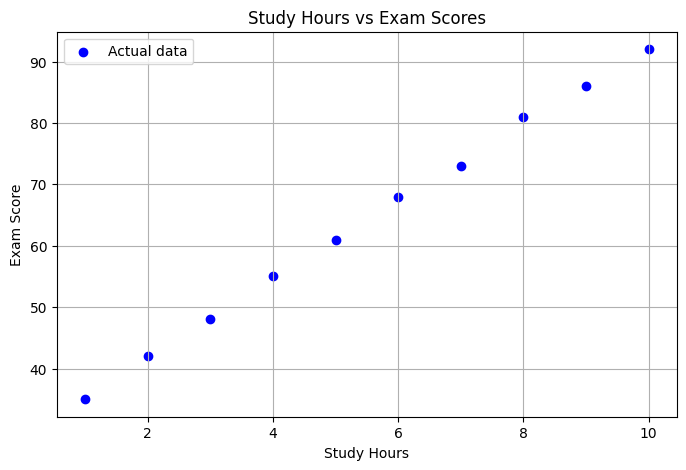

In [55]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, color="blue", label="Actual data")

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.legend()
plt.grid(True)
plt.show()

In [56]:
# Calculate mean and standard deviation of X
X_mean = np.mean(X)
X_std = np.std(X)

# Standardize X
X_scaled = (X - X_mean) / X_std

print("Original X:", X)
print("Standardized X:", X_scaled)

print("\nMean of standardized X:", np.mean(X_scaled))
print("Standard deviation of standardized X:", np.std(X_scaled))

Original X: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
Standardized X: [-1.5666989  -1.21854359 -0.87038828 -0.52223297 -0.17407766  0.17407766
  0.52223297  0.87038828  1.21854359  1.5666989 ]

Mean of standardized X: -6.661338147750939e-17
Standard deviation of standardized X: 1.0


In [57]:
def predict(X, w, b):
    #Predict output using Linear Regression.
    return w * X + b

In [58]:
def mse_loss(y_actual, y_predicted):
    #Calculate Mean Squared Error.
    return np.mean((y_actual - y_predicted) ** 2)

In [59]:
# Initialize parameters
w = 0.0
b = 0.0

# Make predictions
initial_predictions = predict(X_scaled, w, b)

# Calculate initial loss
initial_loss = mse_loss(y, initial_predictions)

print("Initial weight:", w)
print("Initial bias:", b)
print("Initial loss:", initial_loss)

Initial weight: 0.0
Initial bias: 0.0
Initial loss: 4441.3


In [60]:
def compute_gradients(X, y, y_predicted):
    #Calculate gradients for weight and bias.
    n = len(X)

    error = y_predicted - y

    dw = (2 / n) * np.sum(X * error)
    db = (2 / n) * np.sum(error)

    return dw, db

In [61]:
dw, db = compute_gradients(
    X_scaled,
    y,
    initial_predictions
)

print("Gradient of weight (dw):", dw)
print("Gradient of bias (db):", db)

Gradient of weight (dw): -36.45186115712313
Gradient of bias (db): -128.20000000000002


### 1. Batch Gradient Descent

In [62]:
def batch_gradient_descent(X, y, learning_rate, epochs):
    """
    Batch Gradient Descent implementation.
    Uses the entire dataset for every parameter update.
    """

    w = 0.0
    b = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Forward propagation
        y_predicted = predict(X, w, b)

        # Calculate loss
        loss = mse_loss(y, y_predicted)
        loss_history.append(loss)

        # Calculate gradients
        dw, db = compute_gradients(X, y, y_predicted)

        # Update parameters
        w = w - learning_rate * dw
        b = b - learning_rate * db

    return w, b, loss_history

In [63]:
# Training settings
learning_rate = 0.05
epochs = 1000

# Train the model
w_batch, b_batch, batch_loss_history = batch_gradient_descent(
    X_scaled,
    y,
    learning_rate,
    epochs
)

print("Batch Gradient Descent Results")
print("--------------------------------")
print("Weight:", w_batch)
print("Bias:", b_batch)
print("Final Loss:", batch_loss_history[-1])

Batch Gradient Descent Results
--------------------------------
Weight: 18.225930578561545
Bias: 64.09999999999994
Final Loss: 0.305454545454546


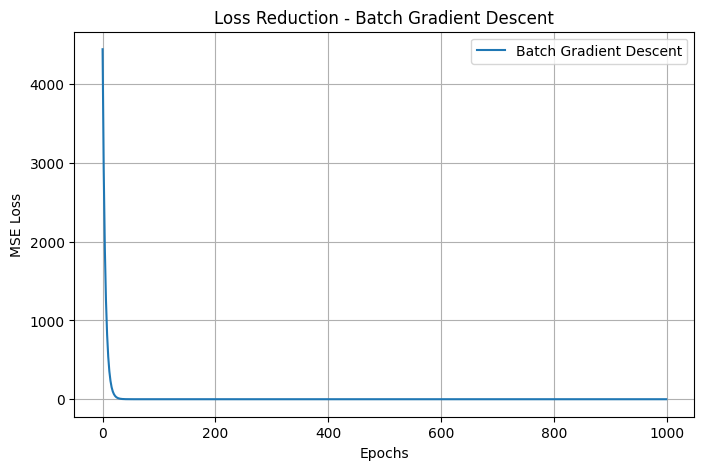

In [64]:
plt.figure(figsize=(8, 5))

plt.plot(batch_loss_history, label="Batch Gradient Descent")

plt.title("Loss Reduction - Batch Gradient Descent")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

### 2. Stochastic Gradient Descent (SGD)

In [65]:
def stochastic_gradient_descent(X, y, learning_rate, epochs, random_state=42):
    """
    Stochastic Gradient Descent implementation.
    Updates parameters using one sample at a time.
    """

    rng = np.random.default_rng(random_state)

    w = 0.0
    b = 0.0

    loss_history = []

    n = len(X)

    for epoch in range(epochs):

        # Shuffle the dataset
        indices = rng.permutation(n)

        for i in indices:

            # Select one sample
            X_sample = X[i]
            y_sample = y[i]

            # Prediction
            y_predicted = w * X_sample + b

            # Calculate gradients for one sample
            error = y_predicted - y_sample

            dw = 2 * X_sample * error
            db = 2 * error

            # Update parameters
            w = w - learning_rate * dw
            b = b - learning_rate * db

        # Calculate loss using the entire dataset after each epoch
        predictions = predict(X, w, b)
        loss = mse_loss(y, predictions)

        loss_history.append(loss)

    return w, b, loss_history

In [66]:
w_sgd, b_sgd, sgd_loss_history = stochastic_gradient_descent(
    X_scaled,
    y,
    learning_rate=0.01,
    epochs=1000
)

print("Stochastic Gradient Descent Results")
print("------------------------------------")
print("Weight:", w_sgd)
print("Bias:", b_sgd)
print("Final Loss:", sgd_loss_history[-1])

Stochastic Gradient Descent Results
------------------------------------
Weight: 18.222872848849427
Bias: 64.09461795339607
Final Loss: 0.3054928615911856


### 3. Mini-Batch Gradient Descent

In [67]:
def mini_batch_gradient_descent(
    X, y, learning_rate, epochs, batch_size=3, random_state=42
):
    """
    Mini-Batch Gradient Descent implementation.
    """

    rng = np.random.default_rng(random_state)

    w = 0.0
    b = 0.0

    loss_history = []

    n = len(X)

    for epoch in range(epochs):

        # Shuffle dataset
        indices = rng.permutation(n)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process mini-batches
        for start in range(0, n, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            y_predicted = predict(X_batch, w, b)

            # Gradients
            dw, db = compute_gradients(
                X_batch,
                y_batch,
                y_predicted
            )

            # Update parameters
            w = w - learning_rate * dw
            b = b - learning_rate * db

        # Calculate full dataset loss
        predictions = predict(X, w, b)
        loss = mse_loss(y, predictions)

        loss_history.append(loss)

    return w, b, loss_history

In [68]:
w_mini, b_mini, mini_loss_history = mini_batch_gradient_descent(
    X_scaled,
    y,
    learning_rate=0.05,
    epochs=1000,
    batch_size=3
)

print("Mini-Batch Gradient Descent Results")
print("-----------------------------------")
print("Weight:", w_mini)
print("Bias:", b_mini)
print("Final Loss:", mini_loss_history[-1])

Mini-Batch Gradient Descent Results
-----------------------------------
Weight: 18.33704406180076
Bias: 64.10176001452139
Final Loss: 0.3178038492632097


### 4. Momentum Gradient Descent

In [69]:
def momentum_gradient_descent(
    X, y, learning_rate, epochs, momentum=0.9
):
    """
    Gradient Descent with Momentum.
    """

    w = 0.0
    b = 0.0

    # Initialize velocities
    velocity_w = 0.0
    velocity_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Predictions
        y_predicted = predict(X, w, b)

        # Loss
        loss = mse_loss(y, y_predicted)
        loss_history.append(loss)

        # Gradients
        dw, db = compute_gradients(
            X,
            y,
            y_predicted
        )

        # Update velocities
        velocity_w = momentum * velocity_w - learning_rate * dw
        velocity_b = momentum * velocity_b - learning_rate * db

        # Update parameters
        w = w + velocity_w
        b = b + velocity_b

    return w, b, loss_history

In [70]:
w_momentum, b_momentum, momentum_loss_history = momentum_gradient_descent(
    X_scaled,
    y,
    learning_rate=0.05,
    epochs=1000,
    momentum=0.9
)

print("Momentum Gradient Descent Results")
print("---------------------------------")
print("Weight:", w_momentum)
print("Bias:", b_momentum)
print("Final Loss:", momentum_loss_history[-1])

Momentum Gradient Descent Results
---------------------------------
Weight: 18.225930578561563
Bias: 64.1
Final Loss: 0.3054545454545466


### Learning-Rate Decay

In [71]:
def momentum_with_decay(
    X,
    y,
    initial_learning_rate,
    epochs,
    momentum=0.9,
    decay_rate=0.01
):
    """
    Momentum Gradient Descent with Learning-Rate Decay.
    """

    w = 0.0
    b = 0.0

    velocity_w = 0.0
    velocity_b = 0.0

    loss_history = []
    learning_rate_history = []

    for epoch in range(epochs):

        # Calculate decayed learning rate
        learning_rate = initial_learning_rate / (
            1 + decay_rate * epoch
        )

        learning_rate_history.append(learning_rate)

        # Predictions
        y_predicted = predict(X, w, b)

        # Loss
        loss = mse_loss(y, y_predicted)
        loss_history.append(loss)

        # Gradients
        dw, db = compute_gradients(
            X,
            y,
            y_predicted
        )

        # Momentum updates
        velocity_w = momentum * velocity_w - learning_rate * dw
        velocity_b = momentum * velocity_b - learning_rate * db

        # Update parameters
        w = w + velocity_w
        b = b + velocity_b

    return w, b, loss_history, learning_rate_history

In [72]:
w_decay, b_decay, decay_loss_history, learning_rate_history = momentum_with_decay(
    X_scaled,
    y,
    initial_learning_rate=0.05,
    epochs=1000,
    momentum=0.9,
    decay_rate=0.01
)

print("Momentum with Learning-Rate Decay Results")
print("------------------------------------------")
print("Weight:", w_decay)
print("Bias:", b_decay)
print("Final Loss:", decay_loss_history[-1])

Momentum with Learning-Rate Decay Results
------------------------------------------
Weight: 18.225930578561574
Bias: 64.10000000000004
Final Loss: 0.3054545454545442


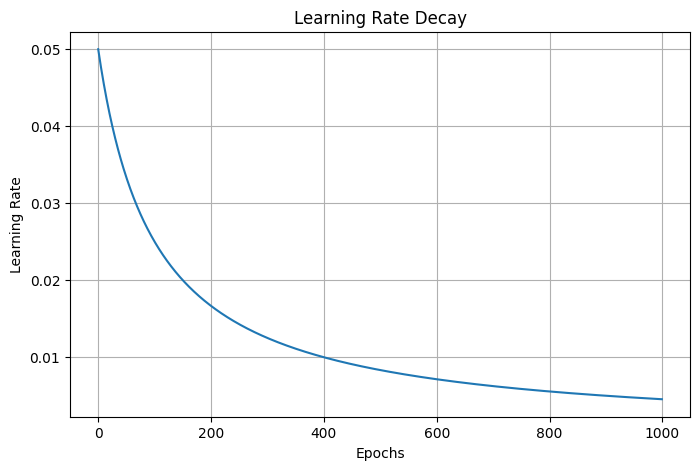

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(learning_rate_history)

plt.title("Learning Rate Decay")
plt.xlabel("Epochs")
plt.ylabel("Learning Rate")

plt.grid(True)
plt.show()

### Comparing all optimization algorithms

In [74]:
results = {
    "Batch Gradient Descent": {
        "weight": w_batch,
        "bias": b_batch,
        "loss": batch_loss_history[-1],
        "history": batch_loss_history
    },

    "Stochastic Gradient Descent": {
        "weight": w_sgd,
        "bias": b_sgd,
        "loss": sgd_loss_history[-1],
        "history": sgd_loss_history
    },

    "Mini-Batch Gradient Descent": {
        "weight": w_mini,
        "bias": b_mini,
        "loss": mini_loss_history[-1],
        "history": mini_loss_history
    },

    "Momentum Gradient Descent": {
        "weight": w_momentum,
        "bias": b_momentum,
        "loss": momentum_loss_history[-1],
        "history": momentum_loss_history
    },

    "Momentum with Learning-Rate Decay": {
        "weight": w_decay,
        "bias": b_decay,
        "loss": decay_loss_history[-1],
        "history": decay_loss_history
    }
}

comparison_df = pd.DataFrame([
    {
        "Optimizer": name,
        "Weight": values["weight"],
        "Bias": values["bias"],
        "Final MSE": values["loss"]
    }
    for name, values in results.items()
])

comparison_df

,Optimizer,Weight,Bias,Final MSE
0,Batch Gradient Descent,18.225931,64.100000,0.305455
1,Stochastic Gradient Descent,18.222873,64.094618,0.305493
2,Mini-Batch Gradient Descent,18.337044,64.101760,0.317804
3,Momentum Gradient Descent,18.225931,64.100000,0.305455
4,Momentum with Learning-Rate Decay,18.225931,64.100000,0.305455


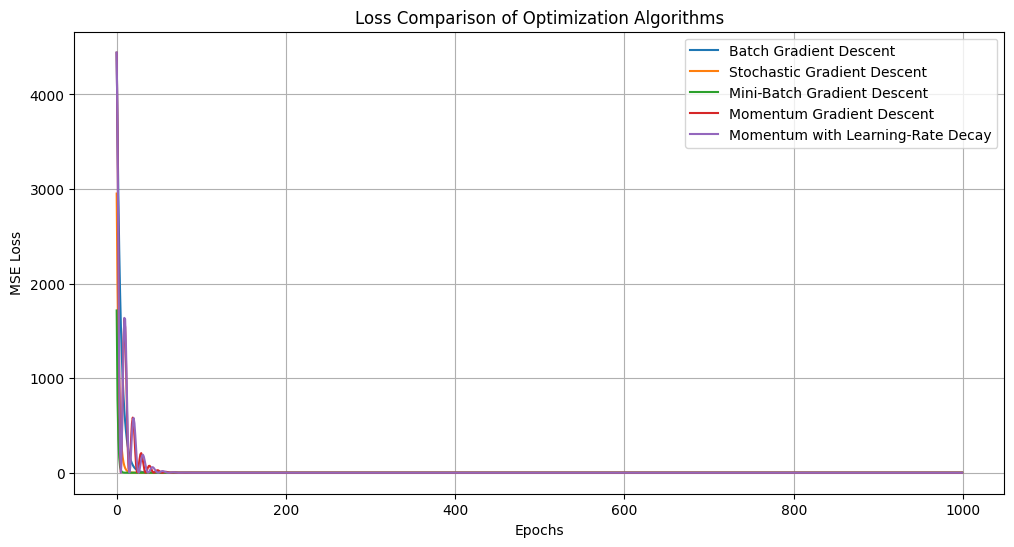

In [75]:
plt.figure(figsize=(12, 6))

for name, values in results.items():
    plt.plot(
        values["history"],
        label=name
    )

plt.title("Loss Comparison of Optimization Algorithms")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

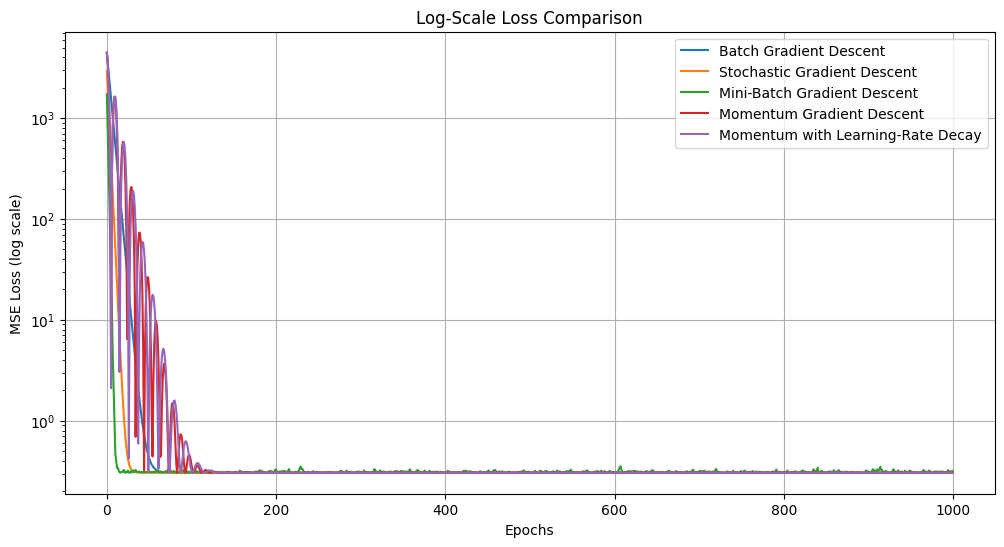

In [76]:
plt.figure(figsize=(12, 6))

for name, values in results.items():
    plt.plot(
        np.maximum(values["history"], 1e-10),
        label=name
    )

plt.yscale("log")

plt.title("Log-Scale Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss (log scale)")

plt.legend()
plt.grid(True)
plt.show()

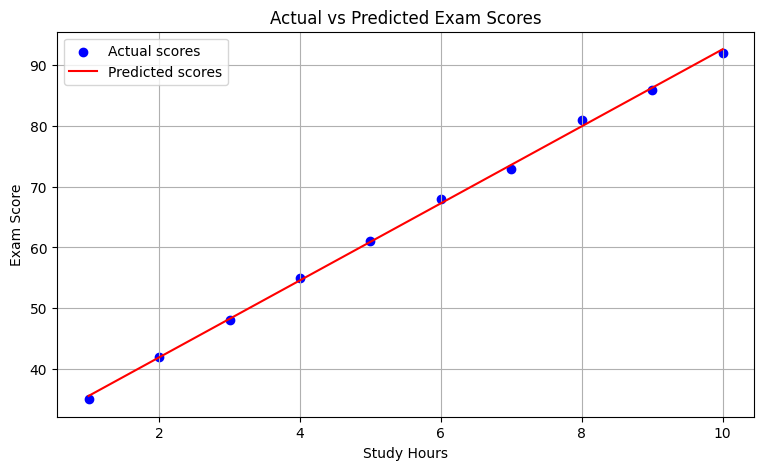

In [77]:
plt.figure(figsize=(9, 5))

plt.scatter(
    X,
    y,
    color="blue",
    label="Actual scores"
)

plt.plot(
    X,
    final_predictions,
    color="red",
    label="Predicted scores"
)

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.legend()
plt.grid(True)
plt.show()

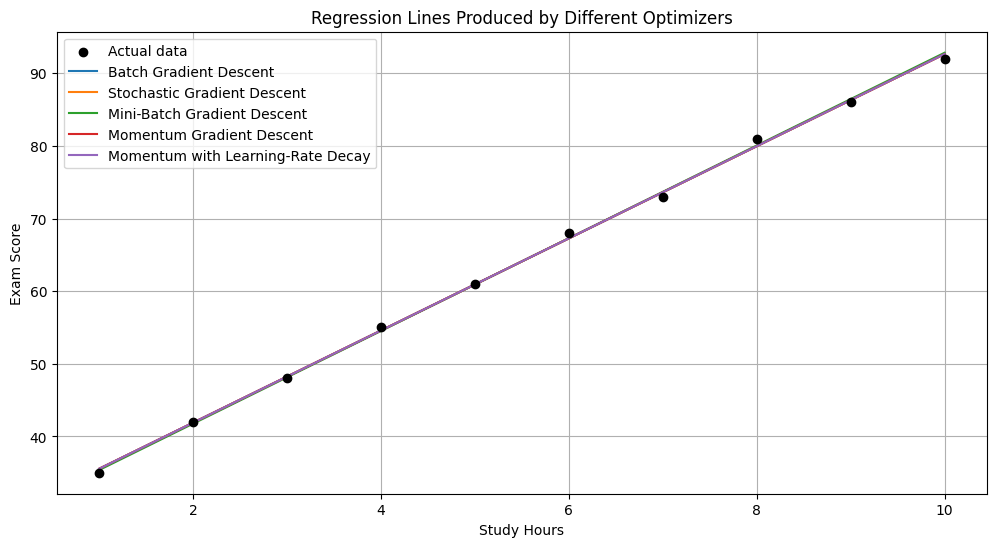

In [78]:
plt.figure(figsize=(12, 6))

plt.scatter(
    X,
    y,
    color="black",
    label="Actual data",
    zorder=5
)

for name, values in results.items():

    predictions = predict(
        X_scaled,
        values["weight"],
        values["bias"]
    )

    plt.plot(
        X,
        predictions,
        label=name
    )

plt.title("Regression Lines Produced by Different Optimizers")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.legend()
plt.grid(True)
plt.show()

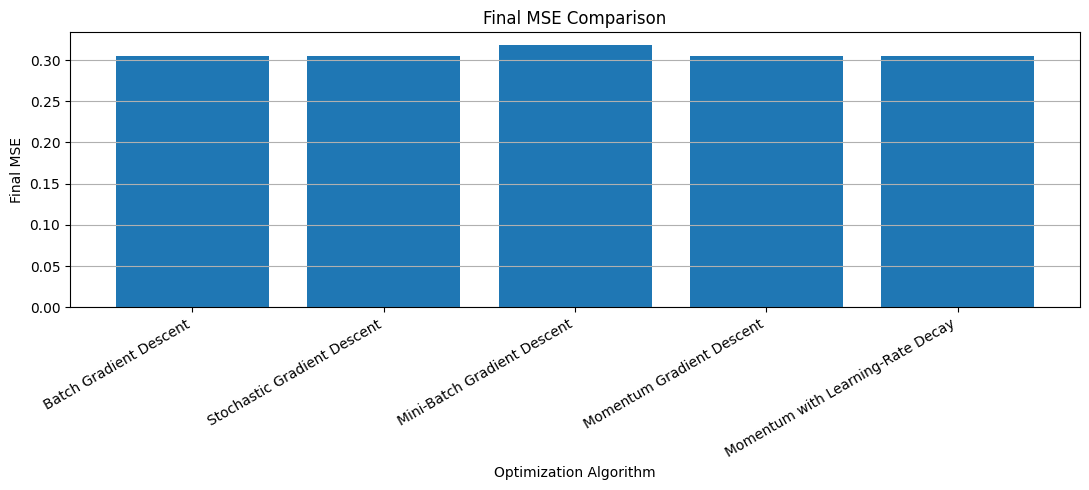

In [79]:
plt.figure(figsize=(11, 5))

optimizer_names = comparison_df["Optimizer"]
final_losses = comparison_df["Final MSE"]

plt.bar(optimizer_names, final_losses)

plt.title("Final MSE Comparison")
plt.xlabel("Optimization Algorithm")
plt.ylabel("Final MSE")

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [80]:
original_parameters = []

for name, values in results.items():

    original_weight = values["weight"] / X_std

    original_bias = (
        values["bias"] -
        (values["weight"] * X_mean / X_std)
    )

    original_parameters.append({
        "Optimizer": name,
        "Original Weight": original_weight,
        "Original Bias": original_bias
    })

original_parameters_df = pd.DataFrame(original_parameters)

original_parameters_df

,Optimizer,Original Weight,Original Bias
0,Batch Gradient Descent,6.345455,29.200000
1,Stochastic Gradient Descent,6.344390,29.200473
2,Mini-Batch Gradient Descent,6.384139,28.988994
3,Momentum Gradient Descent,6.345455,29.200000
4,Momentum with Learning-Rate Decay,6.345455,29.200000
